<a href="https://colab.research.google.com/github/puspendukayal48-lab/reactor-point-kinetics/blob/main/point_kinetics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

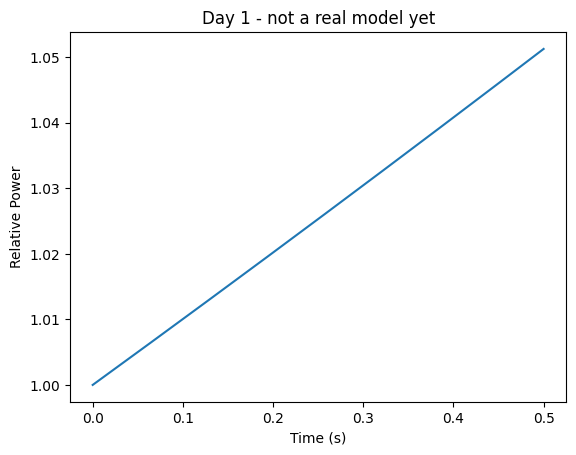

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 0.5, 500)
y = np.exp(0.1*t)  # crude stand-in for reactor power growth
plt.plot(t, y)
plt.xlabel("Time (s)")
plt.ylabel("Relative Power")
plt.title("Day 1 - not a real model yet")
plt.savefig("test.png")
plt.show()

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# Constants (typical values for U-235, one-group delayed neutron approx)
beta = 0.0065       # delayed neutron fraction
Lambda = 1e-5       # prompt neutron generation time (s)
lambda_c = 0.1      # precursor decay constant (1/s)
rho = 0.007         # reactivity (subcritical/supercritical but NOT prompt critical - try small first)

In [ ]:
def point_kinetics(t, y):
    n, C = y
    dndt = ((rho - beta) / Lambda) * n + lambda_c * C
    dCdt = (beta / Lambda) * n - lambda_c * C
    return [dndt, dCdt]

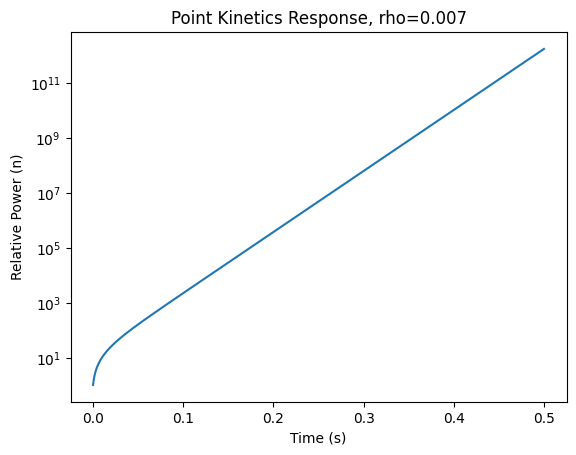

In [ ]:
t_span = (0,20)  # simulate from t=0 to t=20 seconds
y0 = [1, beta/(lambda_c*Lambda)]  # initial condition: n=1 (normalized power), C at equilibrium

sol = solve_ivp(point_kinetics, t_span, y0, t_eval=np.linspace(0, 0.5, 500))

plt.plot(sol.t, sol.y[0])
plt.xlabel("Time (s)")
plt.ylabel("Relative Power (n)")
plt.title("Point Kinetics Response, rho=0.007")
plt.yscale('log')
plt.show()